## Configurando bibliotecas e variáveis de ambiente

In [65]:
lazy from neuron import Neuron
lazy import os
lazy from dotenv import load_dotenv
lazy import numpy as np
lazy import random
lazy import matplotlib.pyplot as plt

In [66]:
load_dotenv()

True

In [67]:
DATASET_PATH = os.getenv("DATASET_PATH_3")
if DATASET_PATH and os.path.exists(DATASET_PATH):
    data = np.load(DATASET_PATH)
else:
    print("Erro: Caminho não encontrado")

In [68]:
print(data)

[[ 1.34834443e+02  9.01428613e-01  1.00000000e+00]
 [ 2.63517819e+02  1.97316968e-01  1.00000000e+00]
 [ 5.61667106e+01 -6.88010959e-01  0.00000000e+00]
 ...
 [ 2.70495031e+02  3.13910313e-01  1.00000000e+00]
 [ 3.44381264e+02 -8.62083967e-01  0.00000000e+00]
 [ 2.05396996e+01 -4.35625851e-01  0.00000000e+00]]


In [69]:
data = data.squeeze()

## Analisando o problema não-linearmente separável

### Com essa função podemos plotar um gráfico e verificar a forma que as classes estão dispostas

In [70]:
def plot_non_linear_problem(dataset):
    
    cls0 = dataset[dataset[:, 2] == 0]
    cls1 = dataset[dataset[:, 2] == 1]

    plt.scatter(cls0[:, 0], cls0[:, 1], color="red", label="Classe 0", s=20)
    plt.scatter(cls1[:, 0], cls1[:, 1], color="blue", label="Classe 1", s=20)

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.show()

### Analisando o gráfico:  
O que define um problema não-linearmente separável é quando nenhuma reta (em 2D) consegue deixar todos os pontos de uma classe de um lado e e todos os da outra classe do outro.  

Observa-se no gráfico plotado que a fronteira entre as classes possui um formato curvilíneo, quase senoidal, indicando que o problema não é linearmente separável.  

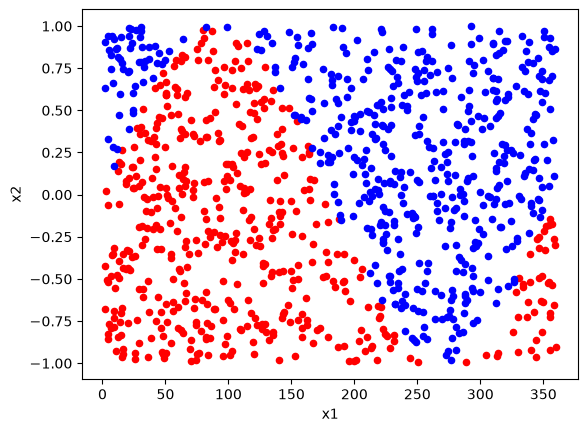

In [71]:
plot_non_linear_problem(data)

## Dividindo o dataset

In [72]:
def holdout(dataset, part_size, seed):
    config_rng = np.random.default_rng(seed)
    config_rng.shuffle(dataset)
    split = int(len(dataset)*part_size)
    train, test = dataset[:split, :], dataset[split:, :]
    return train, test

In [73]:
train, test = holdout(data, 0.7, 3)

In [94]:
class NeuronSon(Neuron):
    def __init__(self, train, test, learning_rate, max_epochs):
        self.dataset = train
        self.X = np.insert(self.dataset[:, :-1], 0, 1, axis=1)
        self.Yd = self.dataset[:, -1]
        self.weights = np.zeros(3, dtype=float)
        self.learning_rate = learning_rate
        self.w_adjust_count = 0
        self.epochs = 0
        self.w_changes = np.empty((0, 3))
        
        self.max_epochs = max_epochs
        self.test_data = test

        self.log_train = []
        self.log_test = []

    def init_weights(self):
        for i in range(3):
            self.weights[i] = random.uniform(-0.5, 0.5)
        print(f"Vetor inicial de pesos: ({self.weights[0]},{self.weights[1]}, {self.weights[2]})")
        
    def train(self, inputs, targets):
        self.init_weights()
        while (self.epochs < self.max_epochs):
            had_error = False
            for xi, yi in zip(inputs, targets):
                output = self.threshold(xi, self.weights)
                error = yi - output
                self.log_train.append({
                    "época": self.epochs + 1,
                    "xi": xi.tolist(),
                    "yi": float(yi),
                    "output": int(output),
                    "error": float(error),
                })
                if error != 0:
                    had_error = True
                    self.w_changes = np.vstack((self.w_changes, self.weights))
                    self.weights = self.adjust_weights(xi, self.weights, error)
                    self.w_adjust_count += 1
            self.epochs += 1
            if not had_error:
                break

    def test(self):
        X_test = np.insert(self.test_data[:, :-1], 0, 1, axis=1)
        Y_test = self.test_data[:, -1]

        hits = 0
        print("Iniciando teste: ")
        for xi, yi in zip(X_test, Y_test):
            output = self.threshold(xi, self.weights)
            if output == yi:
                hits += 1
            self.log_test.append({
                "xi": xi.tolist(),
                "yi": float(yi),
                "output": int(output),
                "acertou": bool(output == yi),
            })

    def export_log(self):
        results = {
            "treino": self.log_train,
            "teste": self.log_test
        }
        with open("results.json", "w", encoding="utf-8") as f:
            json.dump(results, f, indent=4, ensure_ascii=False)
        
    def execute(self):
        self.train(self.X, self.Yd)
        print(f"Vetor final de pesos: {self.weights}")
        print(f"Número total de ajustes no vetor de pesos: {self.w_adjust_count}")
        print(f"Histórico de mudanças do vetor de pesos: {self.w_changes}")
        self.test()
        self.export_log()
        

In [96]:
import json

In [97]:
neuron = NeuronSon(train, test, 0.1, 100)
neuron.execute()

Vetor inicial de pesos: (-0.3485194408847453,0.02338423092076225, 0.38711463163645)
Vetor final de pesos: [-625.14851944    4.23104714  652.98701336]
Número total de ajustes no vetor de pesos: 28650
Histórico de mudanças do vetor de pesos: [[-3.48519441e-01  2.33842309e-02  3.87114632e-01]
 [-4.48519441e-01 -6.69302863e+00  4.30095598e-01]
 [-3.48519441e-01  2.44238684e+01  4.24737579e-01]
 ...
 [-6.25048519e+02  4.25827949e-01  6.52962209e+02]
 [-6.24948519e+02  2.43227909e+01  6.52957135e+02]
 [-6.25048519e+02  1.23168208e+01  6.52977501e+02]]
Iniciando teste: 
